# ReproFlake: dataset preparation and exploratory analysis

This notebook examines the full ReproFlake corpus for supervised flaky-test repair. The training target is an existing fixing patch, not a newly assigned root-cause label.

The corpus contains 1,115 Java/Maven test instances from 140 projects. All 300 source archives and the published execution-results archive are included.

**Units of analysis:** test instances for metadata, unique source–patch pairs for repairs, and separate test/report observations for execution evidence.

**Sources:** [paper](https://arxiv.org/abs/2605.21677), [artifact documentation](https://anonymous.4open.science/r/ReproFlake-C9E6/README.md), source collections [1](https://zenodo.org/records/18474558), [2](https://zenodo.org/records/18634501), [3](https://zenodo.org/records/18605131), and [execution results](https://zenodo.org/records/18451345). Zenodo declares CC BY 4.0. Included project code may have additional licensing requirements.

In [1]:
from pathlib import Path
import logging
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from reproflake_data import (
    acquire_metadata,
    archive_catalog,
    correlation_sensitivity,
    correlations,
    download_corpus,
    execution_results,
    export_pairs,
    inspect_corpus,
    load_metadata,
    paired_execution_summary,
    project_bootstrap,
    project_split,
    session,
    write_json,
)

SEED = 590
DOWNLOAD_WORKERS = 4
MIN_CORRELATION_PAIRS = 15
BOOTSTRAP_REPEATS = 500
ROOT = Path.cwd()
if sys.version_info < (3, 11) or not (ROOT / "reproflake_data.py").is_file():
    raise RuntimeError("Use Python 3.11+ and run from the project directory.")
DATA = ROOT / "data" / "reproflake"
OUT = ROOT / "outputs" / "reproflake"
OUT.mkdir(parents=True, exist_ok=True)
logging.basicConfig(level=logging.WARNING, format="%(levelname)s: %(message)s")
client = session()
sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_colwidth", 75)
SCOPE_LABELS = {"test": "Named test invocations", "report": "XML-report observations"}
MECHANISM_LABELS = {
    "Implementation-dependent": "Implementation\ndependent",
    "Order-dependent": "Order\ndependent",
    "Non-idempotent outcome": "Non-idempotent\noutcome",
    "Time-dependent": "Time\ndependent",
    "Unclassified": "Unclassified",
}

## 1. Acquire and verify the corpus

The 301 archives occupy 47.72 GB. Downloads resume interrupted transfers and verify published sizes and MD5 checksums. SHA-256 fingerprints identify the local copies.

Archives stay compressed. No downloaded scripts, tests, or containers run during EDA. A local patch-application check tests source consistency only.

Cached archives are reverified on each run. This can take several minutes.

In [2]:
provenance = acquire_metadata(client, DATA / "metadata")
cases, cleaning_audit, raw_config = load_metadata(
    DATA / "metadata", OUT / "metadata_cleaning_details.csv"
)
catalog = archive_catalog(DATA / "metadata")
if set(cases.archive_id) != set(catalog.archive_id):
    raise ValueError("Case-to-catalog coverage is incomplete.")
cases = project_split(cases, SEED)
downloads = download_corpus(
    catalog, DATA / "metadata", DATA / "archives", DOWNLOAD_WORKERS
)
if len(downloads) != len(catalog) + 1:
    raise ValueError("Full corpus acquisition is incomplete.")
overview = pd.DataFrame(
    {
        "Quantity": [
            "Test instances",
            "Projects",
            "Source archives",
            "Verified files",
            "Downloaded GB",
        ],
        "Value": [
            len(cases),
            cases.project.nunique(),
            len(catalog),
            len(downloads),
            round(downloads.archive_bytes.sum() / 1e9, 2),
        ],
    }
)
display(overview)
overview.to_csv(OUT / "dataset_overview.csv", index=False)
cases.to_csv(OUT / "case_inventory.csv", index=False)
catalog.to_csv(OUT / "archive_catalog.csv", index=False)
downloads.to_csv(OUT / "verified_downloads.csv", index=False)

,Quantity,Value
0,Test instances,1115.00
1,Projects,140.00
2,Source archives,300.00
3,Verified files,301.00
4,Downloaded GB,47.72


## 2. Variables and coverage

| Variable group | Meaning and use |
|---|---|
| Project, module, test, and original revision | Locate the failing code and define independent evaluation groups. |
| Flakiness mechanism and discovery source | Existing annotations used to assess coverage. They are not new labels. |
| Java version, repetitions, seed, and state-setting test | Conditions for reproducing the failure. |
| Fix revision, pull request, and issue reference | Trace the reference repair. These fields may reveal the solution. |
| Original snapshot and fixing patch | Input material and supervised repair target. |
| Code size, edit size, changed files, and patch hunks | Describe context requirements and repair complexity. |
| Recorded condition, outcome, duration, and invocation | Historical execution evidence, with test and report scopes kept separate. |
| Log files, bytes, lines, and decoding replacements | Describe available context and text quality. |

The field-level dictionaries are exported with the analysis tables.

,tests,projects,archives,test_fraction
category,,,,
Implementation-dependent,819,125,238,73.5%
Order-dependent,126,8,13,11.3%
Non-idempotent outcome,125,3,14,11.2%
Time-dependent,36,10,26,3.2%
Unclassified,9,7,9,0.8%


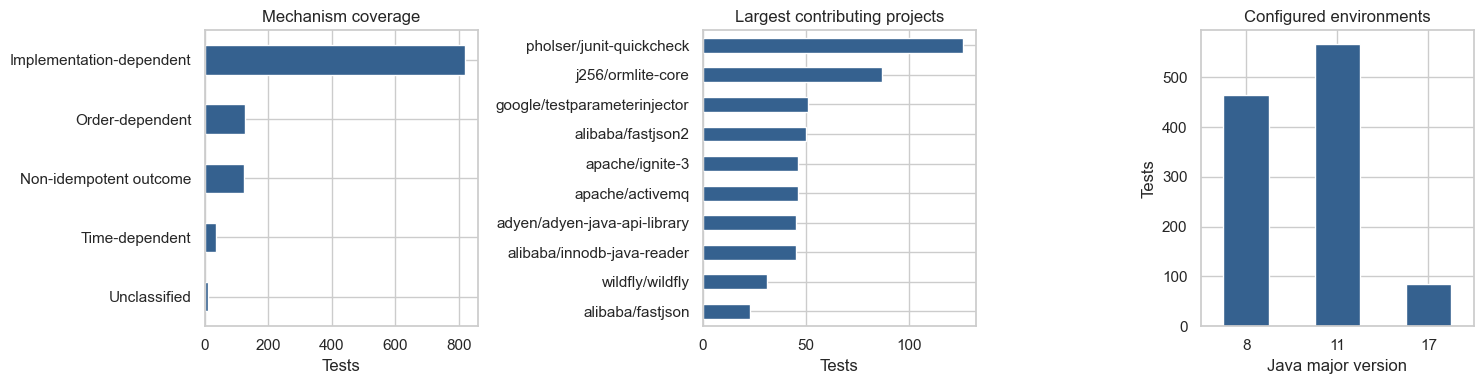

In [3]:
definitions = {
    "case_id": ("Benchmark test identity", "identifier", "Provenance"),
    "test_type": ("Original category spelling", "category", "Audit"),
    "category": ("Canonical existing mechanism", "category", "Coverage"),
    "archive_id": ("Source and reference archive", "identifier", "Grouping"),
    "module": ("Maven module containing the test", "path", "Reproduction"),
    "polluter": ("Preceding state-setting test", "test identity", "Reproduction"),
    "test_name": ("Flaky test class and method", "test identity", "Input retrieval"),
    "iterations": ("Configured repetitions", "count", "Reproduction setting"),
    "execution_config": (
        "Configured execution modes",
        "category",
        "Reproduction setting",
    ),
    "java_version": ("Java major version", "version", "Environment"),
    "nondex_seed": ("Implementation-perturbation seed", "identifier", "Reproduction"),
    "archive_url": (
        "Source-plus-solution archive location",
        "URL",
        "Trusted preparation",
    ),
    "project_url": ("Original project URL", "URL", "Provenance"),
    "project": ("Canonical project identity", "identifier", "Partition grouping"),
    "flaky_commit": ("Original flaky revision", "commit", "Input provenance"),
    "fixed_commit": ("Reference fixing revision", "commit", "Exclude from blind input"),
    "discovery_source": ("Jira or iDoFT origin", "category", "Selection analysis"),
    "fix_pr_url": ("Indexed fixing pull request", "URL", "Exclude from blind input"),
    "issue_url": ("Indexed issue link", "URL", "May reveal the solution"),
    "has_issue_reference": ("Issue link indexed", "boolean", "Availability"),
    "has_fix_pr_reference": ("Fixing PR indexed", "boolean", "Availability"),
    "has_commit_pair": ("Both revisions present and valid", "boolean", "Quality"),
    "has_polluter": ("State-setting test specified", "boolean", "Completeness"),
    "has_seed": ("Perturbation seed specified", "boolean", "Completeness"),
    "tests_per_archive": ("Tests sharing an archive", "count", "Dependence"),
    "split": ("Project-wise partition", "category", "Evaluation control"),
}
if set(cases) != set(definitions):
    raise ValueError("Update the dictionary for the changed schema.")
dictionary = pd.DataFrame(
    [
        {
            "field": field,
            "plain_language_meaning": meaning,
            "units": units,
            "role": role,
            "missing_count": int(cases[field].isna().sum()),
            "missing_fraction": cases[field].isna().mean(),
        }
        for field, (meaning, units, role) in definitions.items()
    ]
)
dictionary.to_csv(OUT / "variable_dictionary.csv", index=False)
coverage = (
    cases.groupby("category")
    .agg(
        tests=("case_id", "size"),
        projects=("project", "nunique"),
        archives=("archive_id", "nunique"),
    )
    .sort_values("tests", ascending=False)
)
coverage["test_fraction"] = coverage.tests / len(cases)
coverage.to_csv(OUT / "category_coverage.csv")
display(coverage.style.format({"test_fraction": "{:.1%}"}))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cases.category.value_counts().sort_values().plot.barh(ax=axes[0], color="#35618f")
axes[0].set(title="Mechanism coverage", xlabel="Tests", ylabel="")
cases.project.value_counts().head(10).sort_values().plot.barh(
    ax=axes[1], color="#35618f"
)
axes[1].set(title="Largest contributing projects", xlabel="Tests", ylabel="")
cases.java_version.value_counts().sort_index().plot.bar(
    ax=axes[2], color="#35618f", rot=0
)
axes[2].set(
    title="Configured environments", xlabel="Java major version", ylabel="Tests"
)
fig.tight_layout()
fig.savefig(OUT / "corpus_coverage.png", dpi=150)
plt.show()

Implementation-dependent tests account for 73.5% of cases. The ten largest projects contribute 49.3% of all tests.

These proportions describe a curated benchmark, not production failure prevalence. Large projects and repeated fixes could dominate training unless examples and evaluation groups are handled carefully.

## 3. Cleaning and cohort construction

Raw files are unchanged. Cleaning creates canonical fields and analysis cohorts; it does not overwrite evidence or invent missing information.

| Check or treatment | Observed result | Handling |
|---|---|---|
| Identity and join checks | 1,115 unique cases; all provenance joins resolve | Stop on duplicate or conflicting identities. Retain every case. |
| Whitespace | Five blank state-setting fields and one revision string | Convert whitespace-only values to missing. Trim the revision before validation. |
| Mechanism spellings | Nine unclassified entries and one brittle-type spelling | Derive a canonical category. Preserve the raw annotation and unknown status. |
| Project identity | Six URLs repeat the Apache owner segment | Correct only the known forms in the canonical identity. Retain the original URL. |
| Reproduction settings and revisions | No invalid positive-integer settings; six missing revision pairs | Validate types and identifiers. Do not replace unavailable revisions. |
| Optional references | 863 cases lack indexed issue and PR links | Preserve missing values. Do not equate an index gap with an absent issue. |
| Execution schemas | Test rows, embedded invocations, and XML-report rows coexist | Parse each format and retain its evidence scope. |
| Execution quality | 160 negative duration sentinels; 100 unknown outcomes | Keep the observations. Set invalid durations missing and exclude unknown outcomes from binary rates. |

Regularization is a modeling choice, not a cleaning step. Imputation is also unnecessary for this descriptive analysis.

In [4]:
cleaning_audit.to_csv(OUT / "cleaning_audit.csv", index=False)
details = pd.read_csv(OUT / "metadata_cleaning_details.csv")
normalizations = details.loc[details.action.ne("Derive canonical mechanism")]
normalization_summary = (
    details.groupby(["action", "field"])
    .agg(events=("case_id", "size"), cases=("case_id", "nunique"))
    .reset_index()
)
display(normalization_summary)
examples = details.drop_duplicates(["action", "field"]).copy()
for column in ["before", "after"]:
    examples[column] = examples[column].map(
        lambda value: "<missing>" if pd.isna(value) else repr(value)
    )
display(examples[["case_id", "field", "before", "after", "action"]])
case_retention = pd.DataFrame(
    {
        "Stage": [
            "Raw case rows",
            "Normalized case rows",
            "Unique case identities",
            "Cases with a revision pair",
        ],
        "Cases": [
            len(raw_config),
            len(cases),
            cases.case_id.nunique(),
            int(cases.has_commit_pair.sum()),
        ],
    }
)
display(case_retention)
normalization_summary.to_csv(OUT / "normalization_summary.csv", index=False)
case_retention.to_csv(OUT / "metadata_retention.csv", index=False)

,action,field,events,cases
0,Derive canonical mechanism,category,10,10
1,Repair canonical project identity,project,6,6
2,Trim whitespace,flaky_commit,1,1
3,Trim whitespace,polluter,5,5


,case_id,field,before,after,action
0,hadoopbb6,polluter,' ',<missing>,Trim whitespace
5,HDFS-15702,flaky_commit,'d4fd675a95c16f6ecd8d8514cc3c0bef34bc9eff ','d4fd675a95c16f6ecd8d8514cc3c0bef34bc9eff',Trim whitespace
6,dubbodubborpcdubborpcdubbo5ea6b331,category,'britle','Order-dependent',Derive canonical mechanism
16,CURATOR-681,project,'https://github.com/apache/apache/curator','apache/curator',Repair canonical project identity


,Stage,Cases
0,Raw case rows,1115
1,Normalized case rows,1115
2,Unique case identities,1115
3,Cases with a revision pair,1109


The ledger records 12 normalization events affecting 12 cases. Ten additional entries document canonical-category derivations, not newly assigned causes.

One case appears in both groups. Event totals therefore do not count distinct cases.

No metadata rows were dropped. The before/after examples make whitespace visible and show exactly which canonical identities changed.

,plain_language_meaning,missing_count,missing_fraction
field,,,
flaky_commit,Original flaky revision,6,0.5%
fixed_commit,Reference fixing revision,6,0.5%
fix_pr_url,Indexed fixing pull request,863,77.4%
issue_url,Indexed issue link,863,77.4%
polluter,Preceding state-setting test,989,88.7%
nondex_seed,Implementation-perturbation seed,296,26.5%


,tests,seed_available,state_setter_available,issue_reference_available,commit_pair_available
category,,,,,
Implementation-dependent,819,100.0%,0.0%,30.4%,99.3%
Non-idempotent outcome,125,0.0%,0.0%,1.6%,100.0%
Order-dependent,126,0.0%,100.0%,0.8%,100.0%
Time-dependent,36,0.0%,0.0%,0.0%,100.0%
Unclassified,9,0.0%,0.0%,0.0%,100.0%


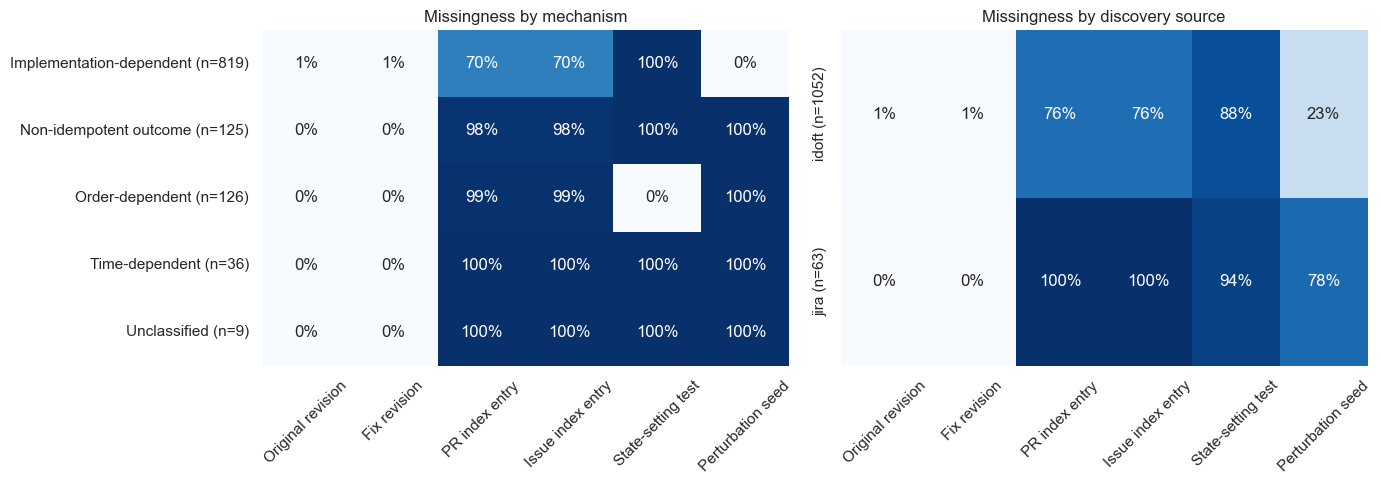

In [5]:
missing_fields = [
    "flaky_commit",
    "fixed_commit",
    "fix_pr_url",
    "issue_url",
    "polluter",
    "nondex_seed",
]
missingness = dictionary.set_index("field").loc[
    missing_fields, ["plain_language_meaning", "missing_count", "missing_fraction"]
]
display(missingness.style.format({"missing_fraction": "{:.1%}"}))
missingness.to_csv(OUT / "metadata_missingness.csv")
conditional = cases.groupby("category").agg(
    tests=("case_id", "size"),
    seed_available=("has_seed", "mean"),
    state_setter_available=("has_polluter", "mean"),
    issue_reference_available=("has_issue_reference", "mean"),
    commit_pair_available=("has_commit_pair", "mean"),
)
conditional.to_csv(OUT / "conditional_completeness.csv")
display(
    conditional.style.format(
        {column: "{:.1%}" for column in conditional if column != "tests"}
    )
)
missing_by_mechanism = cases[missing_fields].isna().groupby(cases.category).mean()
missing_by_source = cases[missing_fields].isna().groupby(cases.discovery_source).mean()
source_counts = cases.discovery_source.value_counts()
field_labels = {
    "flaky_commit": "Original revision",
    "fixed_commit": "Fix revision",
    "fix_pr_url": "PR index entry",
    "issue_url": "Issue index entry",
    "polluter": "State-setting test",
    "nondex_seed": "Perturbation seed",
}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, frame, group_counts, title in [
    (
        axes[0],
        missing_by_mechanism,
        cases.category.value_counts(),
        "Missingness by mechanism",
    ),
    (axes[1], missing_by_source, source_counts, "Missingness by discovery source"),
]:
    plot = frame.rename(columns=field_labels).copy()
    plot.index = [f"{name} (n={group_counts[name]})" for name in frame.index]
    sns.heatmap(
        plot, annot=True, fmt=".0%", vmin=0, vmax=1, cmap="Blues", cbar=False, ax=ax
    )
    ax.set(title=title, xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(OUT / "conditional_missingness.png", dpi=150)
plt.show()
missing_by_mechanism.to_csv(OUT / "missingness_by_mechanism.csv")
missing_by_source.to_csv(OUT / "missingness_by_source.csv")

Seeds are present for implementation-dependent cases. State-setting tests are present for order-dependent cases. Their absence elsewhere is usually structural, not evidence of corrupt records.

The optional URL index covers 252 iDoFT cases and no Jira-origin cases. Jira cases can still originate from issue reports without a joined URL. This is an index-coverage limitation.

A production pipeline should record why a value is missing. It should also reconcile source-specific references before using issue text as model input.

## 4. Inspect reference repairs

Every source archive is inspected. Unique source–patch pairs, rather than test rows, are the repair-analysis unit.

The static patch check does not test behavior. Changed original files are selected using reference paths, so this context must not be used in a blind repair benchmark.

In [6]:
inspection, pairs = inspect_corpus(cases, catalog, downloads, DATA / "pairs")
inspection.to_csv(OUT / "archive_inspection.csv", index=False)
if len(inspection) != len(catalog):
    raise ValueError("Not every archive was inspected.")
successful = inspection.loc[inspection.status.eq("inspected")].copy()
if successful.empty:
    raise RuntimeError("No repair pairs were parsed.")
repairs = successful.drop_duplicates(["originals_sha256", "patch_sha256"]).copy()
archive_categories = cases.groupby("archive_id").category.agg(
    lambda values: values.iloc[0] if values.nunique() == 1 else "Mixed mechanisms"
)
repairs["category"] = repairs.archive_id.map(archive_categories)
pair_audit = export_pairs(pairs, DATA / "reference_pairs")
pair_audit.to_csv(OUT / "pair_export_audit.csv", index=False)
display(
    pd.DataFrame(
        {
            "Measure": [
                "Archives inspected",
                "Archives parsed",
                "Unique pairs",
                "Applicable text references",
                "Mechanically screened pairs",
            ],
            "Count": [
                len(inspection),
                len(successful),
                len(repairs),
                int(repairs.applies_to_snapshot.sum()),
                int(pair_audit.decision.eq("eligible").sum()),
            ],
        }
    )
)
if inspection.status.ne("inspected").any():
    display(
        inspection.loc[
            inspection.status.ne("inspected"), ["archive_id", "status", "reason"]
        ]
    )
repairs.to_csv(OUT / "repair_features.csv", index=False)

,Measure,Count
0,Archives inspected,300
1,Archives parsed,300
2,Unique pairs,300
3,Applicable text references,299
4,Mechanically screened pairs,297


## 5. Prepare execution evidence

Four-field summaries embed repeated calls. Five-field summaries identify tests. Six-field NonDex summaries describe XML reports, not named methods.

Each invocation is preserved. Report-level observations stay separate from named-test observations. Raw condition names and index provenance remain available for audit.

target_cases  recorded_trials  failures  \
version           identity_scope                                            
Fixed             report                   793            79140      6825   
                  test                     292             8080       187   
FixedCodeChange   test                      36             3500      1511   
FixedPassingOrder test                       1               10         0   
Flaky             report                   819            81740     60836   
                  test                     292             8081      2868   
FlakyCodeChange   test                      36             3501      3384   
FlakyPassingOrder test                       1               10        10   

                                  median_case_failure_fraction  
version           identity_scope                                
Fixed             report                                  0.00  
                  test                                    0.00  
FixedCodeChange   test                                    0.00  
FixedPassingOrder test                                    0.00  
Flaky             report                                  0.81  
                  test                                    0.50  
FlakyCodeChange   test                                    1.00  
FlakyPassingOrder test                                    1.00

,Check,Count
0,Parsed observations,186874
1,Linked observations,184322
2,Duplicate observation keys,0
3,Known pass/failure/error observations,184062
4,Missing durations,160
5,Unknown outcomes,100
6,Condition spelling corrections,2520
7,Numeric-format corrections,8


,Observations flagged
issue,
Duration set missing; outcome retained: Negative/nonfinite duration,160
Unknown outcome: unknown,100


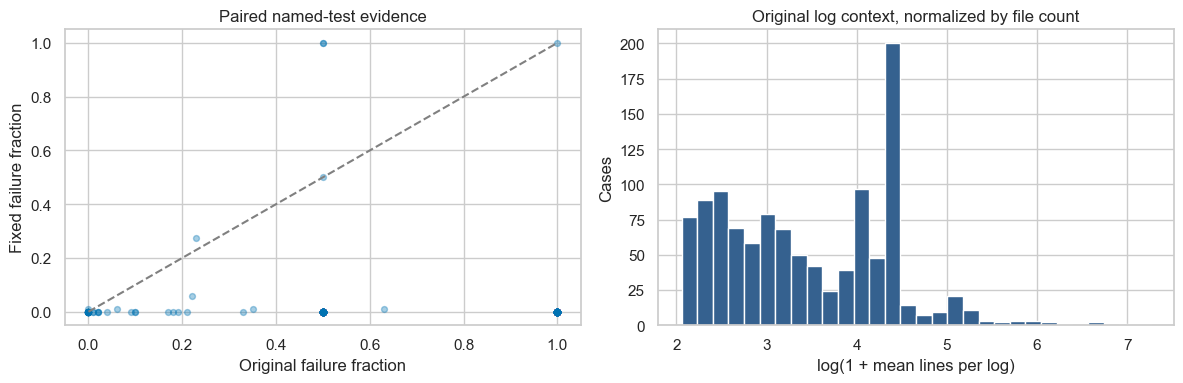

In [7]:
results_path = Path(
    downloads.loc[downloads.archive_id.eq("__execution_results__"), "local_path"].iloc[
        0
    ]
)
log_inventory, trials, execution_issues = execution_results(results_path)
targets = cases[["case_id", "test_name", "project", "archive_id"]].copy()
targets["expected_test"] = targets.test_name.str.replace("#", ".", regex=False)
targets["expected_class"] = targets.expected_test.str.rsplit(".", n=1).str[0]
trials = trials.merge(
    targets.drop(columns="test_name"), on="case_id", how="left", validate="many_to_one"
)
trials["matches_target"] = trials.test_name.eq(trials.expected_test).fillna(False)
trials["matches_report_class"] = trials.reported_class.eq(trials.expected_class).fillna(
    False
)
trials["linked_evidence"] = trials.matches_target | (
    trials.identity_scope.eq("report") & trials.matches_report_class
)
duplicate_trial = trials.duplicated(
    [
        "case_id",
        "version",
        "identity_scope",
        "test_name",
        "round",
        "report_path",
        "invocation",
    ]
)
trials["duplicate_trial"] = duplicate_trial
valid_trials = trials.loc[
    trials.linked_evidence
    & ~duplicate_trial
    & trials.outcome.isin(["passed", "failed", "error"])
].copy()
valid_trials["failed"] = valid_trials.outcome.ne("passed")
case_execution = valid_trials.groupby(["case_id", "version", "identity_scope"]).agg(
    recorded_trials=("outcome", "size"),
    failures=("failed", "sum"),
    median_seconds=("seconds", "median"),
)
case_execution["failure_fraction"] = (
    case_execution.failures / case_execution.recorded_trials
)
version_summary = (
    case_execution.reset_index()
    .groupby(["version", "identity_scope"])
    .agg(
        target_cases=("case_id", "nunique"),
        recorded_trials=("recorded_trials", "sum"),
        failures=("failures", "sum"),
        median_case_failure_fraction=("failure_fraction", "median"),
    )
)
display(version_summary)
execution_quality = pd.DataFrame(
    {
        "Check": [
            "Parsed observations",
            "Linked observations",
            "Duplicate observation keys",
            "Known pass/failure/error observations",
            "Missing durations",
            "Unknown outcomes",
            "Condition spelling corrections",
            "Numeric-format corrections",
        ],
        "Count": [
            len(trials),
            int(trials.linked_evidence.sum()),
            int(duplicate_trial.sum()),
            len(valid_trials),
            int(trials.seconds.isna().sum()),
            int(trials.outcome.eq("unknown").sum()),
            int(trials.version.ne(trials.version_raw).sum()),
            int(trials.duration_format_normalized.sum()),
        ],
    }
)
display(execution_quality)
display(
    execution_issues.groupby("issue").size().rename("Observations flagged").to_frame()
)
execution_quality.to_csv(OUT / "execution_quality_summary.csv", index=False)
execution_issues.to_csv(OUT / "execution_parsing_issues.csv", index=False)
log_inventory.to_csv(OUT / "execution_file_inventory.csv", index=False)
trials.to_csv(OUT / "execution_trials.csv", index=False)
case_execution.to_csv(OUT / "case_execution_summary.csv")
version_summary.to_csv(OUT / "execution_version_summary.csv")
test_execution = case_execution.reset_index().loc[
    lambda frame: frame.identity_scope.eq("test")
]
paired_rates = test_execution.pivot(
    index="case_id", columns="version", values="failure_fraction"
)
original_logs = log_inventory.loc[
    log_inventory.version.eq("Flaky") & log_inventory.case_id.isin(cases.case_id)
].copy()
original_logs["mean_lines_per_log"] = (
    original_logs.log_lines / original_logs.log_files.replace(0, np.nan)
)
original_logs = original_logs.merge(
    cases[["case_id", "category", "project"]], on="case_id", validate="many_to_one"
)
original_logs.to_csv(OUT / "original_log_context.csv", index=False)
if {"Flaky", "Fixed"} <= set(paired_rates):
    paired_rates = paired_rates[["Flaky", "Fixed"]].dropna()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].scatter(paired_rates.Flaky, paired_rates.Fixed, alpha=0.35, s=18)
    axes[0].plot([0, 1], [0, 1], "--", color="gray")
    axes[0].set(
        xlabel="Original failure fraction",
        ylabel="Fixed failure fraction",
        title="Paired named-test evidence",
    )
    axes[1].hist(
        np.log1p(original_logs.mean_lines_per_log.dropna()), bins=30, color="#35618f"
    )
    axes[1].set(
        xlabel="log(1 + mean lines per log)",
        ylabel="Cases",
        title="Original log context, normalized by file count",
    )
    fig.tight_layout()
    fig.savefig(OUT / "published_execution_evidence.png", dpi=150)
    plt.show()

Parsing preserves 186,874 observations. The 160 negative durations become missing, but their skipped outcomes remain recorded. The 100 unknown outcomes are not counted as successes.

Eight locale-formatted durations and 2,520 condition spellings are normalized. The ten-field CSV headers are treated as headers, not observations.

The 2,552 unlinked observations include companion tests. They remain in the exported evidence but do not enter target-case rates. Log length is averaged per file because repetition counts differ across mechanisms.

,References
Parsed references,300
Text/applicability check,299
No remaining build-output edits,298
Final mechanical screen,297


,Observations
Parsed observations,186874
Linked to benchmark targets,184322
Unique linked observations,184322
Known pass/failure/error outcomes,184062


,archive_id,decision
27,BOOKKEEPER-709,quarantined: reference patch does not apply
32,COLLECTIONS-850,quarantined: test suppression requires review
252,wildflynaming3a83b7b,quarantined: generated/build-artifact edits require review


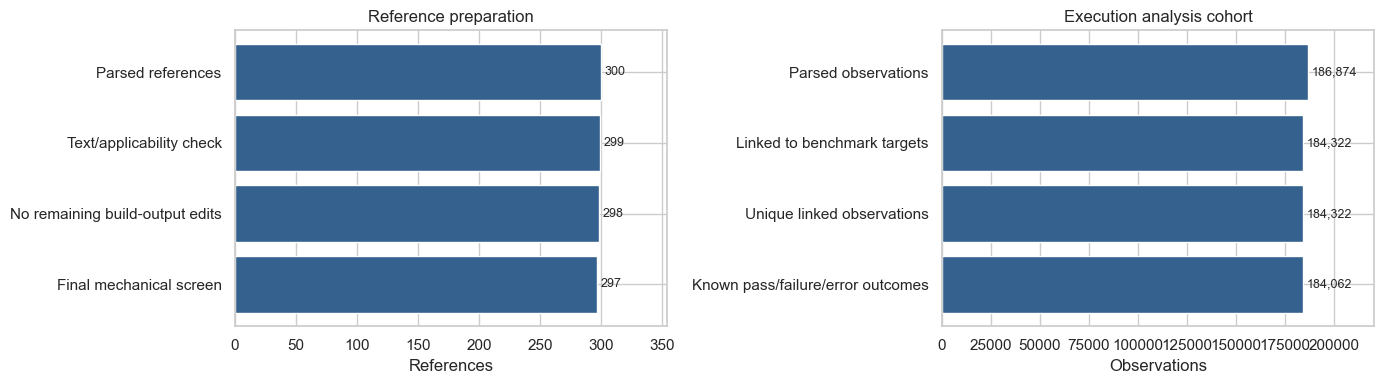

In [8]:
applicable = repairs.applies_to_snapshot
no_build_outputs = applicable & repairs.generated_files_changed.eq(0)
repair_stages = pd.Series(
    {
        "Parsed references": len(repairs),
        "Text/applicability check": int(applicable.sum()),
        "No remaining build-output edits": int(no_build_outputs.sum()),
        "Final mechanical screen": int(pair_audit.decision.eq("eligible").sum()),
    },
    name="References",
)
execution_stages = pd.Series(
    {
        "Parsed observations": len(trials),
        "Linked to benchmark targets": int(trials.linked_evidence.sum()),
        "Unique linked observations": int(
            (trials.linked_evidence & ~duplicate_trial).sum()
        ),
        "Known pass/failure/error outcomes": len(valid_trials),
    },
    name="Observations",
)
display(repair_stages.to_frame())
display(execution_stages.to_frame())
display(pair_audit.loc[pair_audit.decision.ne("eligible"), ["archive_id", "decision"]])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, stages, title in [
    (axes[0], repair_stages, "Reference preparation"),
    (axes[1], execution_stages, "Execution analysis cohort"),
]:
    positions = np.arange(len(stages))
    ax.barh(positions, stages.values, color="#35618f")
    ax.set_yticks(positions, stages.index)
    ax.invert_yaxis()
    ax.set(title=title, xlabel=stages.name, xlim=(0, stages.max() * 1.18))
    for position, count in zip(positions, stages.values):
        ax.text(
            count + stages.max() * 0.01, position, f"{count:,}", va="center", fontsize=9
        )
fig.tight_layout()
fig.savefig(OUT / "cleaning_dispositions.png", dpi=150)
plt.show()
repair_stages.to_csv(OUT / "repair_disposition.csv")
execution_stages.to_csv(OUT / "execution_disposition.csv")

Three references are withheld from text-repair exports: a binary/build-output reference, another generated-output reference, and a suppression-flagged reference.

All 300 remain in corpus-level EDA. The 297 exported pairs pass mechanical checks only. They are not 297 independently validated repairs.

## 6. Repair complexity and relevance to the model

Code and patches provide direct supervision. Test identity and environment support reproduction and context retrieval.

Patch size and edit location describe the target, not information available before a new repair. They help plan context budgets and validation, but must not become blind-input features.

,count,mean,std,min,50%,90%,95%,99%,max
snapshot_java_files,300.0,2564.2,3386.4,15.0,1288.0,6929.2,8665.1,18450.1,20833.0
source_lines,300.0,1535.0,7783.9,26.0,398.5,2277.7,4315.7,15481.3,126712.0
source_characters,300.0,61163.0,283588.9,904.0,15315.0,88233.2,185757.3,597627.0,4518058.0
changed_lines,300.0,298.4,4769.4,1.0,10.5,45.3,77.0,193.0,82627.0
patch_characters,300.0,17449.4,230045.3,596.0,2127.0,6539.8,11028.1,31983.7,3982978.0
files_changed,300.0,6.0,43.2,1.0,1.0,4.0,6.0,26.2,558.0
hunks,300.0,12.8,127.6,1.0,3.0,10.0,15.1,53.2,2207.0


,repairs_flagged,fraction
touches_test,259.000000,86.3%
touches_production,65.000000,21.7%
adds_skip_marker,1.000000,0.3%
deletes_test_file,0.000000,0.0%
adds_sleep,4.000000,1.3%
removes_assertion_line,157.000000,52.3%
has_binary_changes,1.000000,0.3%
edits_generated_outputs,2.000000,0.7%


,archive_id,files_changed,changed_lines,source_lines,binary_files_changed,generated_files_changed
32,COLLECTIONS-850,558,82627,126712,0,0
27,BOOKKEEPER-709,483,538,388,477,483
252,wildflynaming3a83b7b,146,294,35854,0,1
3,adyen-java-api-library=.=b8a8de5,5,192,2990,0,0
52,commons-collections=.=917cdf1,25,188,8718,0,0


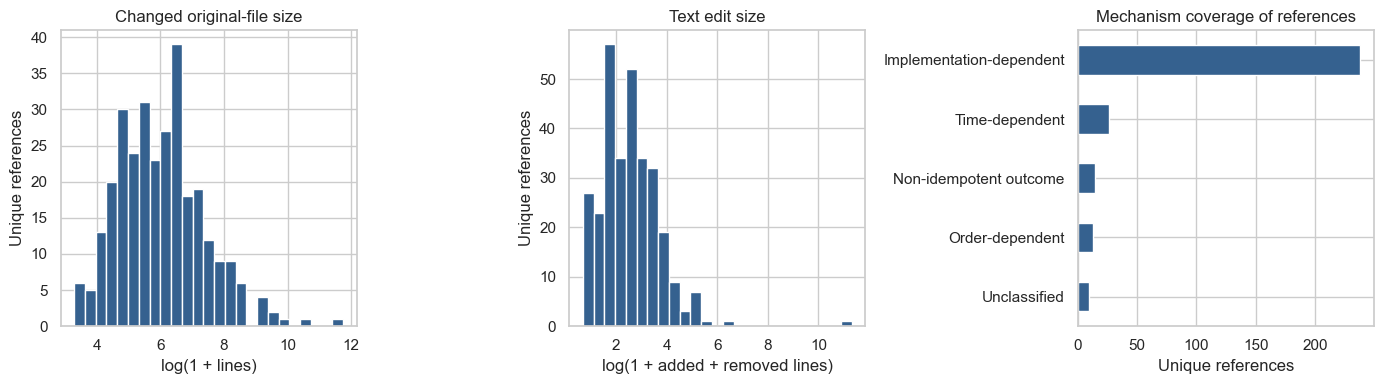

In [9]:
repair_definitions = {
    "snapshot_files": ("Files in the original snapshot", "count"),
    "snapshot_java_files": ("Original Java files", "count"),
    "snapshot_bytes": ("Uncompressed original snapshot", "bytes"),
    "source_lines": ("Lines in changed original text files", "lines"),
    "source_characters": ("Characters in changed originals", "characters"),
    "changed_lines": ("Added plus removed text lines", "lines"),
    "patch_characters": ("Reference patch length", "characters"),
    "files_changed": ("Modified, added, or removed files", "count"),
    "binary_files_changed": ("Non-reconstructible binary differences", "count"),
    "generated_files_changed": ("Edits under target or build directories", "count"),
    "hunks": ("Contiguous edit regions", "count"),
    "lines_added": ("Text lines added", "lines"),
    "lines_removed": ("Text lines removed", "lines"),
    "removed_assertion_lines": ("Removed assertion/failure-call lines", "lines"),
    "added_assertion_lines": ("Added assertion/failure-call lines", "lines"),
    "touches_test": ("Edits Maven test sources", "boolean"),
    "touches_production": ("Edits Maven production sources", "boolean"),
    "adds_skip_marker": ("Adds Ignore or Disabled annotations", "boolean"),
    "deletes_test_file": ("Deletes a whole test-source file", "boolean"),
    "adds_sleep": ("Adds a Thread.sleep call", "boolean"),
    "applies_to_snapshot": ("Passes the static patch check", "boolean"),
}
pd.DataFrame(
    [
        {
            "field": field,
            "plain_language_meaning": meaning,
            "units": units,
            "missing_fraction": repairs[field].isna().mean(),
            "role": "Reference-derived analysis; not blind input",
        }
        for field, (meaning, units) in repair_definitions.items()
    ]
).to_csv(OUT / "repair_variable_dictionary.csv", index=False)
numeric_features = [
    "snapshot_java_files",
    "source_lines",
    "source_characters",
    "changed_lines",
    "patch_characters",
    "files_changed",
    "hunks",
]
repair_summary = (
    repairs[numeric_features]
    .astype(float)
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .T
)
display(repair_summary.round(1))
repair_summary.to_csv(OUT / "repair_size_summary.csv")
screening_fields = [
    "touches_test",
    "touches_production",
    "adds_skip_marker",
    "deletes_test_file",
    "adds_sleep",
]
screening = pd.DataFrame(
    {
        "repairs_flagged": repairs[screening_fields].sum().astype(int),
        "fraction": repairs[screening_fields].mean(),
    }
)
for field, flag in [
    ("removes_assertion_line", repairs.removed_assertion_lines.gt(0)),
    ("has_binary_changes", repairs.binary_files_changed.gt(0)),
    ("edits_generated_outputs", repairs.generated_files_changed.gt(0)),
]:
    screening.loc[field] = [int(flag.sum()), flag.mean()]
display(screening.style.format({"fraction": "{:.1%}"}))
screening.to_csv(OUT / "repair_screening.csv")
largest = repairs.nlargest(5, "changed_lines")[
    [
        "archive_id",
        "files_changed",
        "changed_lines",
        "source_lines",
        "binary_files_changed",
        "generated_files_changed",
    ]
]
display(largest)
largest.to_csv(OUT / "largest_reference_patches.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(np.log1p(repairs.source_lines.astype(float)), bins=25, color="#35618f")
axes[0].set(
    title="Changed original-file size",
    xlabel="log(1 + lines)",
    ylabel="Unique references",
)
axes[1].hist(np.log1p(repairs.changed_lines.astype(float)), bins=25, color="#35618f")
axes[1].set(
    title="Text edit size",
    xlabel="log(1 + added + removed lines)",
    ylabel="Unique references",
)
repairs.category.value_counts().sort_values().plot.barh(ax=axes[2], color="#35618f")
axes[2].set(
    title="Mechanism coverage of references", xlabel="Unique references", ylabel=""
)
fig.tight_layout()
fig.savefig(OUT / "repair_characteristics.png", dpi=150)
plt.show()

,references,median_edits,multi_file_fraction,production_fraction
category,,,,
Implementation-dependent,238,9.500000,39.1%,22.3%
Non-idempotent outcome,14,7.000000,21.4%,7.1%
Order-dependent,13,14.000000,84.6%,15.4%
Time-dependent,26,32.000000,57.7%,19.2%
Unclassified,9,45.000000,44.4%,44.4%


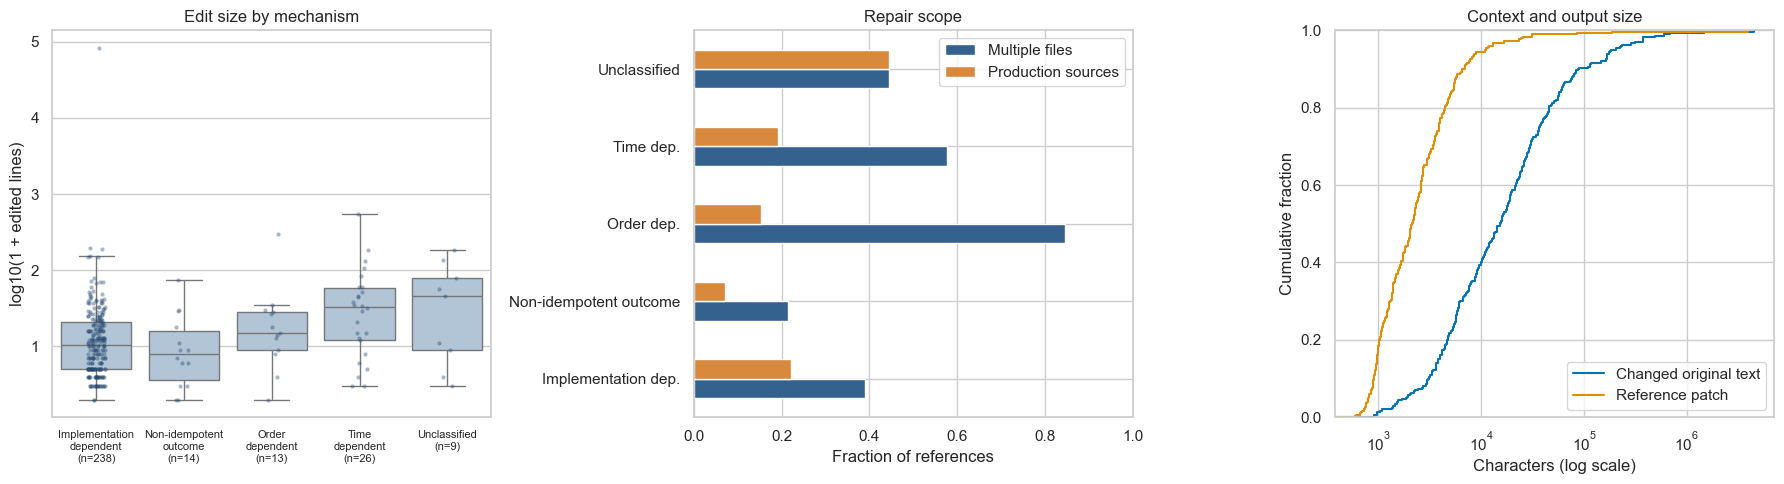

In [10]:
mechanism_repairs = repairs.groupby("category").agg(
    references=("archive_id", "size"),
    median_edits=("changed_lines", "median"),
    multi_file_fraction=("files_changed", lambda values: values.gt(1).mean()),
    production_fraction=("touches_production", "mean"),
)
display(
    mechanism_repairs.style.format(
        {"multi_file_fraction": "{:.1%}", "production_fraction": "{:.1%}"}
    )
)
mechanism_repairs.to_csv(OUT / "repair_complexity_by_mechanism.csv")
order = mechanism_repairs.index.tolist()
plot_data = repairs.assign(log_edits=np.log10(1 + repairs.changed_lines.astype(float)))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(
    data=plot_data,
    x="category",
    y="log_edits",
    order=order,
    showfliers=False,
    color="#aac5de",
    ax=axes[0],
)
np.random.seed(SEED)
sns.stripplot(
    data=plot_data,
    x="category",
    y="log_edits",
    order=order,
    size=3,
    alpha=0.4,
    color="#284a70",
    ax=axes[0],
)
axes[0].set_xticks(
    np.arange(len(order)),
    [
        f"{MECHANISM_LABELS.get(name, name)}\n(n={mechanism_repairs.loc[name, 'references']})"
        for name in order
    ],
)
axes[0].set(title="Edit size by mechanism", xlabel="", ylabel="log10(1 + edited lines)")
axes[0].tick_params(axis="x", labelsize=8)
rates = mechanism_repairs[["multi_file_fraction", "production_fraction"]].rename(
    columns={
        "multi_file_fraction": "Multiple files",
        "production_fraction": "Production sources",
    }
)
rates.index = [name.replace("-dependent", " dep.") for name in rates.index]
rates.plot.barh(ax=axes[1], xlim=(0, 1), color=["#35618f", "#d9893e"])
axes[1].set(title="Repair scope", xlabel="Fraction of references", ylabel="")
for field, label in [
    ("source_characters", "Changed original text"),
    ("patch_characters", "Reference patch"),
]:
    sns.ecdfplot(x=repairs[field].astype(float), ax=axes[2], label=label)
axes[2].set(
    xscale="log",
    xlabel="Characters (log scale)",
    ylabel="Cumulative fraction",
    title="Context and output size",
)
axes[2].legend()
fig.tight_layout()
fig.savefig(OUT / "repair_mechanism_context.png", dpi=150)
plt.show()

The median reference changes 10.5 lines. The 95th percentile is 77 lines, but the largest changes 82,627. Broad snapshot differences need review before SFT conversion.

Eleven of 13 order-dependent references change multiple files. This is a small group, not a universal repair rule. Across the corpus, 65 references touch production code.

Context retrieval should therefore support repository-level investigation. Character counts are not tokenizer counts, and assertion-removal flags are not proof of weakening.

## 7. Compare original and fixed conditions fairly

Use only cases with both conditions in the same evidence scope. Otherwise, missing fixed runs can change the comparison cohort.

Case-weighted means give each case equal weight. Pooled rates give more weight to cases with more recorded observations. Both are reported.

Project resampling preserves each case's paired conditions. Its interval describes sensitivity to project composition, not a causal effect or uncertainty about this census.

,identity_scope,original_cases,fixed_cases,paired_cases,projects,original_case_mean,fixed_case_mean,mean_reduction,reduction_low,reduction_high
0,report,819,793,793,125,0.747,0.086,0.660,0.555,0.747
1,test,292,292,292,22,0.652,0.013,0.639,0.340,0.877


,identity_scope,original_case_mean,original_pooled_rate,fixed_case_mean,fixed_pooled_rate
0,report,0.747,0.746,0.086,0.086
1,test,0.652,0.355,0.013,0.023


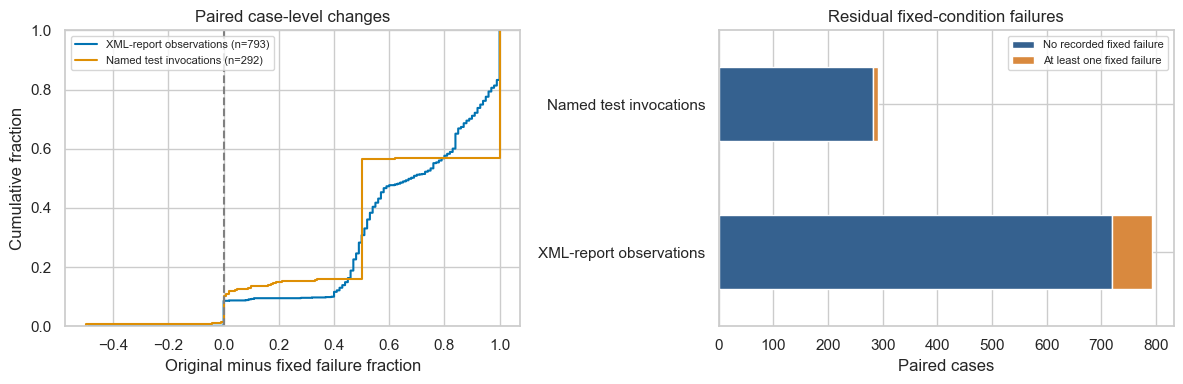

In [11]:
paired_cases, paired_summary = paired_execution_summary(
    case_execution.reset_index(), cases, SEED, BOOTSTRAP_REPEATS
)
paired_cases.to_csv(OUT / "paired_case_outcomes.csv", index=False)
paired_summary.to_csv(OUT / "paired_outcome_summary.csv", index=False)
display_columns = [
    "identity_scope",
    "original_cases",
    "fixed_cases",
    "paired_cases",
    "projects",
    "original_case_mean",
    "fixed_case_mean",
    "mean_reduction",
    "reduction_low",
    "reduction_high",
]
display(paired_summary[display_columns].round(3))
display(
    paired_summary[
        [
            "identity_scope",
            "original_case_mean",
            "original_pooled_rate",
            "fixed_case_mean",
            "fixed_pooled_rate",
        ]
    ].round(3)
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for scope, group in paired_cases.groupby("identity_scope"):
    sns.ecdfplot(
        x=group.rate_reduction,
        ax=axes[0],
        label=f"{SCOPE_LABELS[scope]} (n={len(group)})",
    )
axes[0].axvline(0, color="gray", linestyle="--")
axes[0].set(
    xlabel="Original minus fixed failure fraction",
    ylabel="Cumulative fraction",
    title="Paired case-level changes",
)
axes[0].legend(fontsize=8)
residual = paired_summary.set_index("identity_scope")[
    ["fixed_cases_without_failures", "fixed_cases_with_failures"]
].rename(
    columns={
        "fixed_cases_without_failures": "No recorded fixed failure",
        "fixed_cases_with_failures": "At least one fixed failure",
    }
)
residual.index = residual.index.map(SCOPE_LABELS)
residual.plot.barh(stacked=True, ax=axes[1], color=["#35618f", "#d9893e"])
axes[1].set(xlabel="Paired cases", ylabel="", title="Residual fixed-condition failures")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "paired_outcomes.png", dpi=150)
plt.show()

The paired cohorts contain 793 report-level cases from 125 projects and 292 named-test cases from 22 projects. The report cohort excludes 26 original-only cases.

Case-weighted failure fractions fall from 74.7% to 8.6% for reports and from 65.2% to 1.3% for named tests. These are publisher observations, not agent results.

Residual failures appear in 73 report-level cases and ten named-test cases. Reference patches still require independent validation.

For named tests, the original pooled rate is 35.5%, well below the 65.2% case-weighted mean. Unequal repetition counts make weighting consequential.

## 8. Relationships and sensitivity

Spearman correlations summarize skewed structural measurements. Identifiers and algebraically redundant measures are excluded.

The primary analysis retains all 300 references. Two sensitivity cohorts remove mechanically withheld references or edits above the 99th percentile.

These checks do not redefine cleaning. They test whether a few unusual references drive the descriptive relationships.

,left,right,spearman,paired_repairs,projects,absolute_spearman
4,Edited lines,Patch hunks,0.780,300,140,0.780
5,Changed files,Patch hunks,0.752,300,140,0.752
3,Edited lines,Changed files,0.548,300,140,0.548
1,Original-file lines,Changed files,0.527,300,140,0.527
2,Original-file lines,Patch hunks,0.457,300,140,0.457
0,Original-file lines,Edited lines,0.421,300,140,0.421


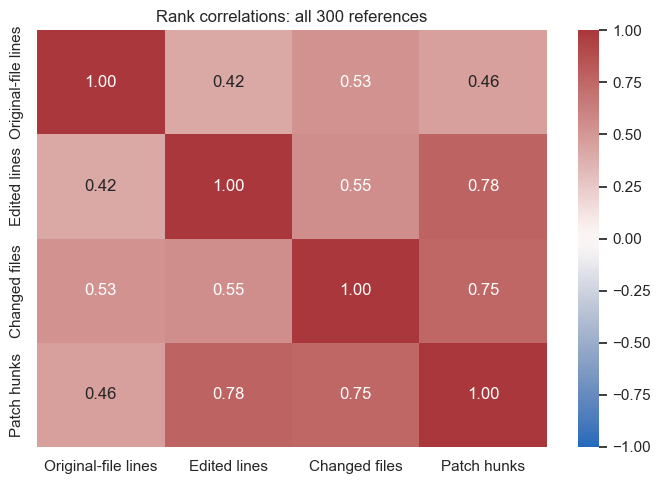

In [12]:
relation_columns = ["source_lines", "changed_lines", "files_changed", "hunks"]
labels = {
    "source_lines": "Original-file lines",
    "changed_lines": "Edited lines",
    "files_changed": "Changed files",
    "hunks": "Patch hunks",
}
corr, associations = correlations(repairs, relation_columns, MIN_CORRELATION_PAIRS)
associations["absolute_spearman"] = associations.spearman.abs()
associations = associations.sort_values("absolute_spearman", ascending=False)
interval = None
if not associations.empty:
    top = associations.iloc[0]
    interval = project_bootstrap(repairs, top.left, top.right, SEED, BOOTSTRAP_REPEATS)
    display(
        associations.assign(
            left=associations.left.map(labels), right=associations.right.map(labels)
        ).round(3)
    )
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(
        corr.rename(index=labels, columns=labels),
        mask=corr.isna().to_numpy(),
        vmin=-1,
        vmax=1,
        cmap="vlag",
        annot=True,
        fmt=".2f",
        ax=ax,
    )
    ax.set_title("Rank correlations: all 300 references")
    fig.tight_layout()
    fig.savefig(OUT / "repair_correlations.png", dpi=150)
    plt.show()
corr.to_csv(OUT / "spearman_matrix.csv")
associations.to_csv(OUT / "pairwise_associations.csv", index=False)
write_json(
    OUT / "bootstrap_interval.json",
    {
        "interval": interval,
        "seed": SEED,
        "repeats": BOOTSTRAP_REPEATS,
        "scope": "Project-composition stability, not census sampling uncertainty",
    },
)

,cohort,repairs,projects,excluded_repairs,edit_size_cutoff
0,Full corpus,300,140,0,NaN
1,Mechanically screened,297,139,3,NaN
2,Below 99th-percentile edit size,297,139,3,193.02


cohort                       Below 99th-percentile edit size  Full corpus  \
left          right                                                         
changed_lines files_changed                            0.533        0.548   
              hunks                                    0.775        0.780   
files_changed hunks                                    0.745        0.752   
source_lines  changed_lines                            0.412        0.421   
              files_changed                            0.520        0.527   
              hunks                                    0.446        0.457   

cohort                       Mechanically screened  
left          right                                 
changed_lines files_changed                  0.533  
              hunks                          0.775  
files_changed hunks                          0.745  
source_lines  changed_lines                  0.412  
              files_changed                  0.520  
              hunks                          0.446

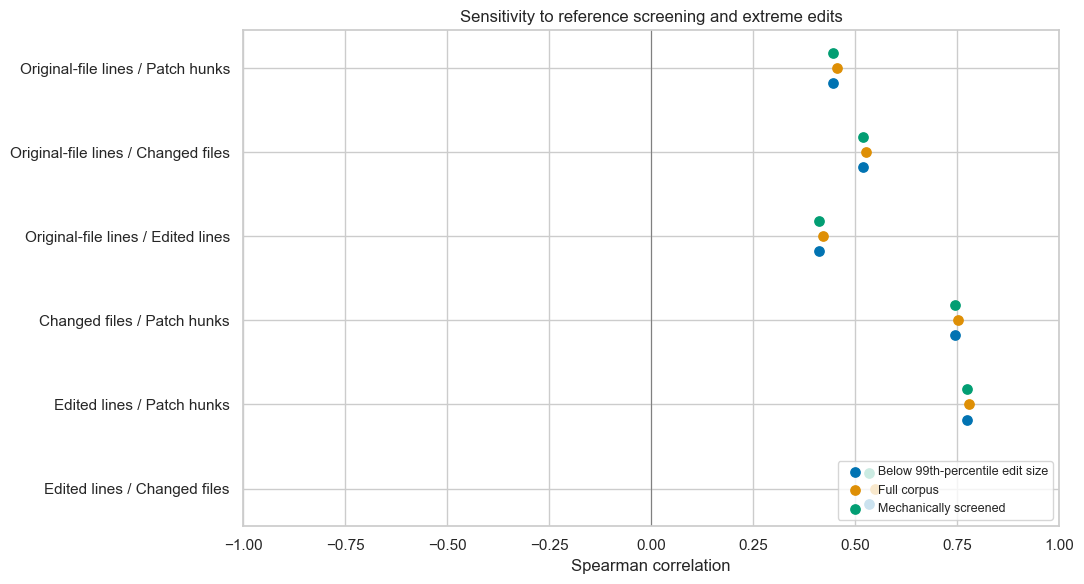

In [13]:
sensitivity, sensitivity_coverage = correlation_sensitivity(
    repairs, pair_audit, relation_columns, MIN_CORRELATION_PAIRS
)
display(sensitivity_coverage)
comparison = sensitivity.pivot(
    index=["left", "right"], columns="cohort", values="spearman"
)
display(comparison.round(3))
fig, ax = plt.subplots(figsize=(11, 6))
pair_order = comparison.index.tolist()
for offset, cohort in zip([-0.18, 0, 0.18], comparison.columns):
    ax.scatter(
        comparison[cohort], np.arange(len(pair_order)) + offset, label=cohort, s=45
    )
ax.set_yticks(
    np.arange(len(pair_order)),
    [f"{labels[left]} / {labels[right]}" for left, right in pair_order],
)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(
    xlim=(-1, 1),
    xlabel="Spearman correlation",
    title="Sensitivity to reference screening and extreme edits",
)
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "correlation_sensitivity.png", dpi=150)
plt.show()
sensitivity.to_csv(OUT / "correlation_sensitivity.csv", index=False)
sensitivity_coverage.to_csv(OUT / "sensitivity_cohorts.csv", index=False)

Edited lines and patch hunks have the strongest association: rho = 0.78. Changed files and hunks are also strongly related.

The largest three references are the same three withheld by the mechanical screen. Removing them changes each coefficient by less than 0.02.

These relationships describe repair structure, not causal mechanisms. Avoid treating correlated summaries as independent evidence. Patch-derived values remain target-side analysis, not blind-input predictors.

## 9. Evaluation partitions and leakage

Projects are assigned approximately 70%/15%/15% to training, validation, and test. Related tests and archives stay in one partition.

Case counts need not match those percentages. The split-composition figure makes this difference explicit.

Reference patches, fixing revisions, solution-bearing issues, and fixed-condition outcomes are excluded from blind inputs. Exact checks cover the full corpus; fork and near-duplicate checks remain necessary.

,projects,tests,archives,test_fraction
split,,,,
train,98,869,222,77.9%
validation,21,64,32,5.7%
test,21,182,46,16.3%


References
split      decision                                                              
test       eligible                                                            45
           quarantined: generated/build-artifact edits require review           1
train      eligible                                                           222
validation eligible                                                            30
           quarantined: reference patch does not apply                          1
           quarantined: test suppression requires review                        1

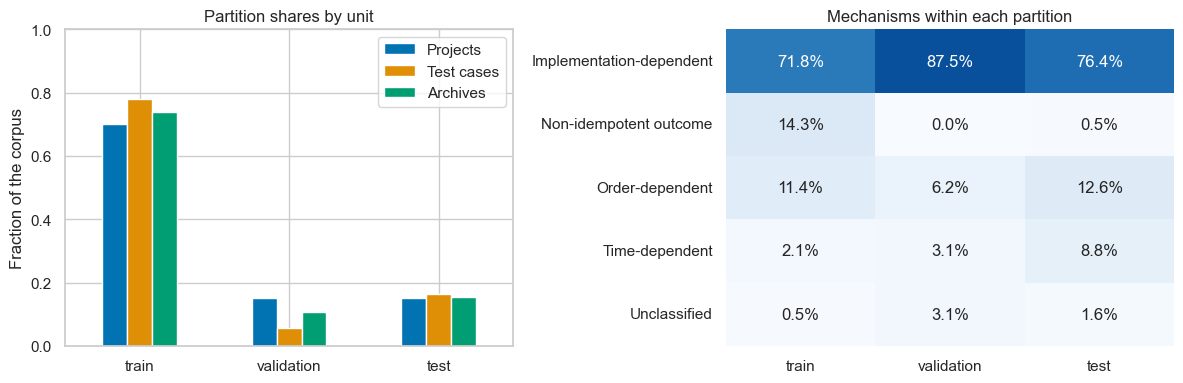

In [14]:
split_order = ["train", "validation", "test"]
split_summary = (
    cases.groupby("split")
    .agg(
        projects=("project", "nunique"),
        tests=("case_id", "size"),
        archives=("archive_id", "nunique"),
    )
    .reindex(split_order)
)
split_summary["test_fraction"] = split_summary.tests / len(cases)
if (
    cases.groupby("project").split.nunique().max() != 1
    or cases.groupby("archive_id").split.nunique().max() != 1
):
    raise AssertionError("Project/archive partition leakage.")
display(split_summary.style.format({"test_fraction": "{:.1%}"}))
display(
    pair_audit.groupby(["split", "decision"]).size().rename("References").to_frame()
)
split_summary.to_csv(OUT / "project_split_summary.csv")
cases[["case_id", "project", "archive_id", "split"]].to_csv(
    OUT / "split_assignments.csv", index=False
)
blind_fields = [
    "case_id",
    "project",
    "archive_id",
    "flaky_commit",
    "test_name",
    "module",
    "java_version",
    "iterations",
    "nondex_seed",
    "polluter",
    "split",
]
cases.loc[cases.split.ne("train"), blind_fields].to_csv(
    OUT / "blind_holdout_cases.csv", index=False
)
mechanism_counts = pd.crosstab(cases.category, cases.split).reindex(columns=split_order)
mechanism_proportions = mechanism_counts.div(mechanism_counts.sum(axis=0), axis=1)
shares = split_summary[["projects", "tests", "archives"]].div(
    split_summary[["projects", "tests", "archives"]].sum()
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
shares.rename(
    columns={"projects": "Projects", "tests": "Test cases", "archives": "Archives"}
).plot.bar(ax=axes[0], rot=0)
axes[0].set(
    title="Partition shares by unit",
    ylabel="Fraction of the corpus",
    xlabel="",
    ylim=(0, 1),
)
sns.heatmap(
    mechanism_proportions,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    cbar=False,
    ax=axes[1],
)
axes[1].set(title="Mechanisms within each partition", xlabel="", ylabel="")
fig.tight_layout()
fig.savefig(OUT / "split_composition.png", dpi=150)
plt.show()
mechanism_counts.to_csv(OUT / "mechanism_by_partition.csv")
mechanism_proportions.to_csv(OUT / "mechanism_partition_proportions.csv")
write_json(
    OUT / "analysis_provenance.json",
    {
        "source_metadata": provenance,
        "seed": SEED,
        "scope": "Full published corpus",
        "verified_files": len(downloads),
        "verified_bytes": int(downloads.archive_bytes.sum()),
        "cases": len(cases),
        "projects": cases.project.nunique(),
        "source_archives_parsed": len(successful),
        "source_archives_attempted": len(inspection),
        "unique_inspected_pairs": len(repairs),
        "execution_observations": len(trials),
        "execution_trial_rows": len(trials),
        "linked_evidence_cases": trials.loc[
            trials.linked_evidence, "case_id"
        ].nunique(),
        "usable_outcome_cases": valid_trials.case_id.nunique(),
        "usable_binary_cases": valid_trials.case_id.nunique(),
        "python": sys.version,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "validation": "Published evidence analyzed; no independent benchmark execution.",
    },
)
client.close()

## Conclusions

- The full corpus provides 300 reference pairs. Mechanical screening retains 297; it does not establish repair correctness.
- Missingness reflects both reproduction design and source-specific indexing. Retaining these distinctions is safer than blanket imputation.
- Repair sizes are highly skewed. Context budgets and target quality need review before fine-tuning.
- Paired publisher outcomes support validation planning, not claims about this project's agents.
- Project-wise evaluation limits direct leakage, but case imbalance and near-duplicate risks remain.

Next steps are tokenizer-based preparation and isolated reproduction, perturbation, and regression testing. Compare the original and fine-tuned model under the same agent workflow.